In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D3/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,126324,0.20,0.87,99.46,1.72,1096,125228,3181,6,cosine,[title],1024,0,1,salted_qgrams,,4
1,Matching with cosine,230324,0.15,0.48,99.55,0.95,1097,229227,3182,5,cosine,[title],1024,0,1,salted_qgrams,,4
2,Matching with cosine,513690,0.10,0.21,99.73,0.43,1099,512591,3184,3,cosine,[title],1024,0,1,salted_qgrams,,4
3,Matching with cosine,66348,0.25,1.64,98.82,3.23,1089,65259,3174,13,cosine,[title],1024,0,1,salted_qgrams,,4
4,Matching with cosine,34848,0.30,3.10,98.09,6.01,1081,33767,3166,21,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Matching with scm,3892846,0.35,0.03,99.82,0.06,1100,3891746,3185,2,scm,[title],1024,0,32,salted_qgrams,,4
2428,Matching with scm,3972735,0.20,0.03,100.00,0.06,1102,3971633,3187,0,scm,[title],1024,0,32,salted_qgrams,,4
2429,Matching with scm,3967962,0.25,0.03,100.00,0.06,1102,3966860,3187,0,scm,[title],1024,0,32,salted_qgrams,,4
2430,Matching with scm,3949395,0.30,0.03,99.91,0.06,1101,3948294,3186,1,scm,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
12,Matching with cosine,1382,0.70,39.36,49.36,43.80,544,838,2629,558,cosine,[title],1024,0,1,salted_qgrams,,4
614,Matching with dice,1721,0.65,34.17,53.36,41.66,588,1133,2673,514,dice,[title],1024,0,1,salted_qgrams,,4
1225,Matching with jaccard,1598,0.50,35.61,51.63,42.15,569,1029,2654,533,jaccard,[title],1024,0,1,salted_qgrams,,4
1824,Matching with scm,1751948,0.95,0.06,97.46,0.12,1074,1750874,3159,28,scm,[title],1024,0,1,salted_qgrams,,4
29,Matching with cosine,1425,0.70,38.95,50.36,43.93,555,870,2640,547,cosine,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2397,Matching with scm,1531,0.80,32.07,44.56,37.30,491,1040,2576,611,scm,[title],1024,0,31,salted_qgrams,,4
591,Matching with cosine,642,0.90,39.10,22.78,28.78,251,391,2336,851,cosine,[title],1024,0,32,salted_qgrams,,4
1202,Matching with dice,610,0.90,40.33,22.32,28.74,246,364,2331,856,dice,[title],1024,0,32,salted_qgrams,,4
1810,Matching with jaccard,831,0.80,31.77,23.96,27.32,264,567,2349,838,jaccard,[title],1024,0,32,salted_qgrams,,4


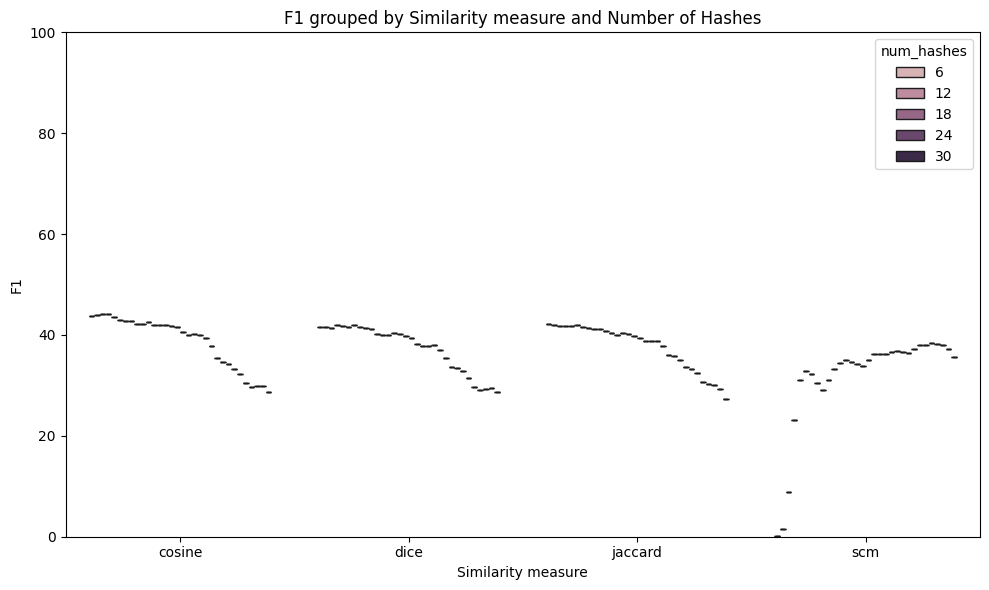

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,39.36
1,dice,1,Precision %,34.17
2,jaccard,1,Precision %,35.61
3,scm,1,Precision %,0.06
4,cosine,2,Precision %,38.95
...,...,...,...,...
379,scm,31,F1 %,37.30
380,cosine,32,F1 %,28.78
381,dice,32,F1 %,28.74
382,jaccard,32,F1 %,27.32


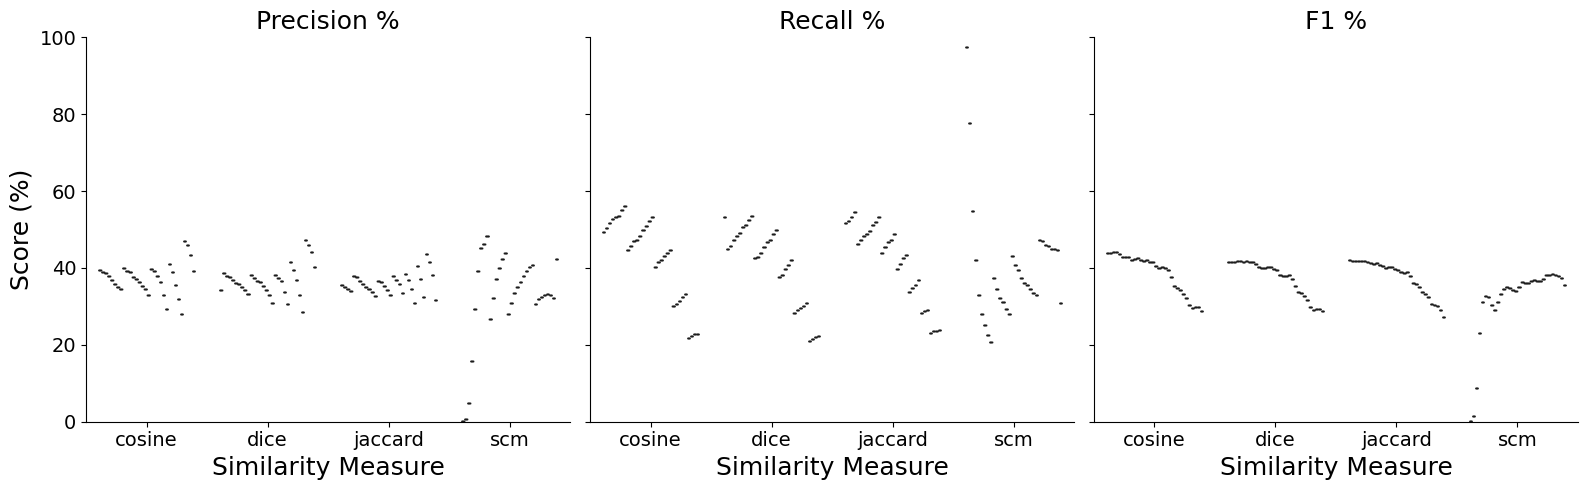

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

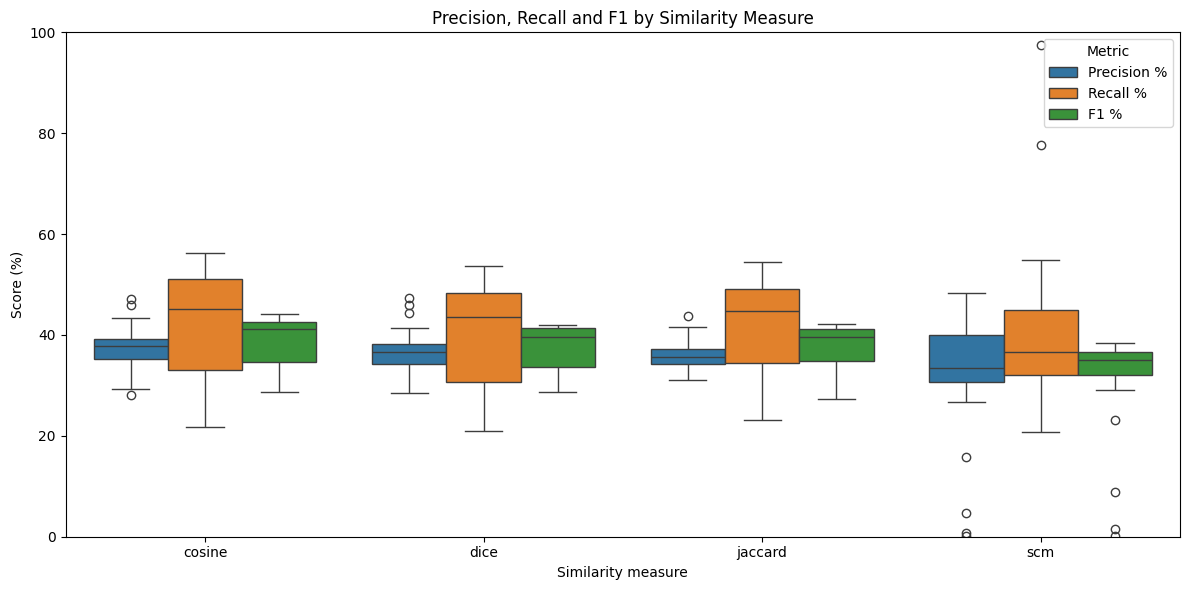

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()